# Estado del arte: modelos de cartera estructurales, actuariales y de eventos raros, y la brecha de código abierto

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 01 a 06 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- nombrar las familias de modelos de crédito de cartera de la literatura que encontró la investigación (estructurales, actuariales, el límite de la cartera grande y su ajuste por granularidad, simulación de eventos raros) y decir cuáles corre Contraste y cuáles no;
- comparar cinco de ellas en una cartera con una calibración, en capital al 99% y al 99,9%, y leer las razones que informa el caso como sus cifras de impacto;
- decir qué implica el resultado de Gordy sobre las dos familias para la comparación, y hasta dónde llega este cuaderno al probarlo;
- sopesar la incertidumbre del insumo de correlación frente a la elección del modelo, en capital;
- enunciar la brecha de código abierto que encontró la investigación, con su fecha y sus límites.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# El cuaderno está tres carpetas por debajo de la raíz del repositorio
ROOT = Path("../../..").resolve()

for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))


riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Siete archivos versionados del caso C10 (propietario: este repositorio; las tasas de pérdida detrás de los ajustes vienen de la tabla `chgallsa` de la Reserva Federal, https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm, dominio público, clase de licencia `mirror-allowed`):

- los cinco archivos por tipo de préstamo en `data/derived/C10/`, cada uno con la escalera versionada de peldaños C1 a C6 sobre la cartera ilustrativa de ese tipo de préstamo (una cartera construida, nunca la de un banco), el bloque de granularidad y las cifras de `impact`;
- `models-c10.json`: la definición de la escalera, los peldaños con su función del motor y su referencia, y los parámetros del caso;
- `grid-22.json`: la grilla del simulador del cuaderno 06, de la que leemos el tamaño medido del intervalo de correlación.

Aquí no se repite ninguna simulación: las corridas de Monte Carlo de tamaño completo se leen como están versionadas, y solo se recalculan los peldaños analíticos. La celda siguiente carga los archivos e imprime la escalera tal como la define el caso.

In [2]:
# Cargar los archivos e imprimir la escalera del caso con sus funciones del motor y sus referencias
NAMES = {
    "commercial-industrial": "Comerciales e industriales",
    "commercial-real-estate": "Inmobiliario comercial",
    "residential": "Inmobiliario residencial",
    "credit-cards": "Tarjetas de crédito",
    "other-consumer": "Otro consumo",
}
LANG = "es"
read = lambda name: json.loads((ROOT / "data" / "derived" / "C10" / f"{name}.json").read_text(encoding="utf-8"))
docs = {k: read(k) for k in NAMES}
models = read("models-c10")
grid22 = read("grid-22")
print("calculado con riskvalidation", {d["provenance"]["riskvalidation_version"] for d in docs.values()})
print(f"{'peldaño':6s} {'método':30s} {'estimador':12s} función del motor")
for row in models["fit"]["ladder"]:
    print(f"{row['rung']:6s} {row['method']:30s} {row['estimator']:12s} {row['engine_function'].replace('riskvalidation.', '')}")

calculado con riskvalidation {'0.7.0'}
peldaño método                         estimador    función del motor
C1     lhp-vasicek                    analytic     portfolio.portfolio.lhp_measures
C2     gaussian-copula-one-factor     monte-carlo  portfolio.copula.simulate_gaussian
C2     gaussian-copula-multi-factor   monte-carlo  portfolio.copula.simulate_gaussian
C3     student-t-copula               monte-carlo  portfolio.copula.simulate_student_t
C4     creditrisk-plus                analytic     portfolio.creditrisk_plus.pmf_stable
C5     granularity-adjustment         analytic     portfolio.granularity.granularity_adjustment
C6     importance-sampling            monte-carlo  portfolio.importance.importance_sample_gaussian
C6     importance-sampling            monte-carlo  portfolio.importance.importance_sample_gaussian


## Método

La comparación está construida para que los modelos difieran en una sola cosa, su estructura, y en nada más. Cada peldaño de la escalera toma **la misma cartera** (tres grupos de nombres idénticos, 1.120 nombres, 100 millones de USD, LGD 45%), **la misma PD y correlación** (el ajuste de máxima verosimilitud del cuaderno 02) y los mismos niveles de cuantil. Lo que cambia cada peldaño:

| Peldaño | Modelo | Cambio respecto del anterior |
|---|---|---|
| C1 | cartera homogénea grande | el límite en forma cerrada: infinitos nombres, un factor |
| C2 | cópula gaussiana, un factor | la cartera finita, simulada |
| C2 | cópula gaussiana, dos sectores | dos factores sectoriales correlacionados en lugar de uno |
| C3 | cópula t de Student, 5 grados de libertad | dependencia de cola |
| C4 | CreditRisk+, recursión estable | un modelo actuarial con factor Gamma, resuelto exactamente |
| C5 | límite de la cartera grande más el ajuste por granularidad | el límite en forma cerrada, corregido por concentración |
| C6 | muestreo por importancia, cópula gaussiana | el mismo modelo que C2, muestreado para alcanzar la cola |

El Paso 1 lista los peldaños de la cartera comercial al 99% y al 99,9% con su razón al límite, y recalcula los dos peldaños analíticos baratos de correr, C1 y C4, para compararlos con los versionados. El Paso 2 recalcula, a partir de las filas de los peldaños, las razones que el caso informa como sus cifras de impacto. El Paso 3 repite las razones para los cinco tipos de préstamo. La primera celda es el Paso 1.

In [3]:
# Listar los peldaños versionados de la cartera comercial con su razón al límite y recalcular los dos peldaños analíticos baratos
from riskvalidation.portfolio import creditrisk_plus as cr
from riskvalidation.portfolio.portfolio import lhp_measures

ci = docs["commercial-industrial"]["outputs"]
rungs = {r["id"]: r for r in ci["rungs"]}
book = ci["portfolio"]
pd_hat = ci["fit"]["maximum_likelihood"]["pd"]["estimate"]
rho_hat = ci["fit"]["maximum_likelihood"]["rho"]["estimate"]
limit_999 = rungs["c1-lhp"]["measures"][1]["var"]

print(f"{'peldaño':20s} {'VaR 99%':>11s} {'ES 99%':>11s} {'VaR 99.9%':>11s} {'ES 99.9%':>11s} {'VaR 99.9% / límite':>22s}")
for rid in ("c1-lhp", "c2-gaussian-1f", "c2-gaussian-mf", "c3-student-t", "c4-creditrisk-plus", "c5-granularity", "c6-is-gaussian"):
    m99, m999 = rungs[rid]["measures"]
    es99 = f"{m99['es']:11,.0f}" if m99["es"] is not None else f"{'-':>11s}"
    es999 = f"{m999['es']:11,.0f}" if m999["es"] is not None else f"{'-':>11s}"
    print(f"{rid:20s} {m99['var']:11,.0f} {es99} {m999['var']:11,.0f} {es999} {m999['var'] / limit_999:22.3f}")

# Recalcular C1 y C4 con el motor y comparar
c1 = lhp_measures(book["total_ead"], book["lgd_mean"], pd_hat, rho_hat, (0.99, 0.999))
crp = rungs["c4-creditrisk-plus"]
sigma2 = next(p["value"] for p in crp["parameters"] if p["name"] == "sigma2")
loss_unit = next(p["value"] for p in crp["parameters"] if p["name"] == "loss_unit")
ead = np.concatenate([np.full(g["n_names"], g["ead_each"]) for g in book["groups"]])
pd_names = np.concatenate([np.full(g["n_names"], g["pd"]) for g in book["groups"]])
inp = cr.CreditRiskPlusInput(nu=np.rint(ead * book["lgd_mean"] / loss_unit).astype(int), pd=pd_names, w0=np.zeros(ead.size), weights=np.ones((ead.size, 1)),
                             sigma2=np.array([sigma2]), loss_unit=loss_unit, currency=book["currency"])
pmf = cr.pmf_stable(inp, int(next(d["value"] for d in crp["diagnostics"] if d["name"] == "n_max")))
c4 = cr.measures_from_pmf(pmf, loss_unit, (0.99, 0.999))
for label, mine, committed in (("C1", c1, rungs["c1-lhp"]["measures"]), ("C4", c4, crp["measures"])):
    print(label, "mayor diferencia en VaR y ES con el peldaño versionado:", f"{max(max(abs(m.var - c['var']), abs(m.es - c['es'])) for m, c in zip(mine, committed)):.2e}")

peldaño                  VaR 99%      ES 99%   VaR 99.9%    ES 99.9%     VaR 99.9% / límite
c1-lhp                 1,500,956   1,844,768   2,298,834   2,680,019                  1.000
c2-gaussian-1f         2,097,000   2,569,386   3,177,000   3,683,187                  1.382
c2-gaussian-mf         2,007,000   2,453,580   3,033,000   3,495,384                  1.319
c3-student-t           6,210,000   9,198,133  13,095,000  16,000,767                  5.696
c4-creditrisk-plus     2,079,000   2,514,778   3,078,000   3,506,025                  1.339
c5-granularity         1,982,727           -   3,281,809           -                  1.428
c6-is-gaussian         2,097,000   2,577,268   3,204,000   3,710,983                  1.394
C1 mayor diferencia en VaR y ES con el peldaño versionado: 4.25e-03
C4 mayor diferencia en VaR y ES con el peldaño versionado: 5.34e-03


El caso resume la comparación en unas pocas razones, guardadas en cada archivo bajo `impact`. Cada una es un cociente de dos filas de peldaños, así que se puede recalcular desde las filas y compararla con el valor guardado. El Paso 2 lo hace para la cartera comercial: la cópula t de Student sobre la cópula gaussiana y la cópula gaussiana sobre el límite (ambas al 99,9%), el ajuste por granularidad como parte de la exposición, y el capital ajustado sobre el capital IRB. Agrega también CreditRisk+ sobre la cópula gaussiana, que el caso informa en un hallazgo.

In [4]:
# Recalcular las razones de impacto desde las filas de los peldaños y compararlas con los valores guardados
def var999(doc, rid):
    return next(r for r in doc["outputs"]["rungs"] if r["id"] == rid)["measures"][1]["var"]

impact = docs["commercial-industrial"]["impact"]
recomputed = {
    "var_999_student_t_over_gaussian": var999(docs["commercial-industrial"], "c3-student-t") / var999(docs["commercial-industrial"], "c2-gaussian-1f"),
    "var_999_gaussian_over_lhp": var999(docs["commercial-industrial"], "c2-gaussian-1f") / var999(docs["commercial-industrial"], "c1-lhp"),
    "ga_999_share": ci["granularity"]["levels"][1]["ga"],
    "ec_ratio_fitted_to_irb": ci["irb_reference"]["ec_lhp_fitted"] / ci["irb_reference"]["k_irb"],
}
print(f"{'razón':36s} {'recalculada':>14s} {'guardada':>12s}")
for name, value in recomputed.items():
    print(f"{name:36s} {value:14.6f} {impact[name]['value']:12.6f}")
print("CreditRisk+ sobre la cópula gaussiana, VaR 99.9%:", round(var999(docs["commercial-industrial"], "c4-creditrisk-plus") / var999(docs["commercial-industrial"], "c2-gaussian-1f"), 4))

razón                                   recalculada     guardada
var_999_student_t_over_gaussian            4.121813     4.121813
var_999_gaussian_over_lhp                  1.382005     1.382005
ga_999_share                               0.009830     0.009830
ec_ratio_fitted_to_irb                     0.335915     0.335915
CreditRisk+ sobre la cópula gaussiana, VaR 99.9%: 0.9688


El Paso 3 repite las mismas razones para los cinco tipos de préstamo. Las carteras difieren en tamaño, concentración y parámetros ajustados, así que las razones muestran cuánto de la comparación pertenece a la estructura de los modelos y cuánto a la cartera.

In [5]:
# Imprimir las mismas razones para los cinco tipos de préstamo, con el número efectivo de nombres de cada cartera
print(f"{'tipo de préstamo':26s} {'nombres efect.':>14s} {'t / Gauss.':>10s} {'Gauss. / LHP':>12s} {'CRP / Gauss.':>12s} {'GA / LHP':>9s} {'ajustado / IRB':>16s}")
for key, label in NAMES.items():
    doc_k = docs[key]
    imp = doc_k["impact"]
    ratio_crp = var999(doc_k, "c4-creditrisk-plus") / var999(doc_k, "c2-gaussian-1f")
    ga_over_lhp = doc_k["outputs"]["granularity"]["levels"][1]["ga_money"] / var999(doc_k, "c1-lhp")
    print(f"{label:26s} {doc_k['outputs']['portfolio']['effective_names']:14.0f} {imp['var_999_student_t_over_gaussian']['value']:10.2f} {imp['var_999_gaussian_over_lhp']['value']:12.2f} {ratio_crp:12.3f} {ga_over_lhp:9.3f} {imp['ec_ratio_fitted_to_irb']['value']:16.3f}")
print("fuente del capital K en el ajuste por granularidad:", {d["outputs"]["granularity"]["k_source"] for d in docs.values()})

tipo de préstamo           nombres efect. t / Gauss. Gauss. / LHP CRP / Gauss.  GA / LHP   ajustado / IRB
Comerciales e industriales            104       4.12         1.38        0.969     0.428            0.336
Inmobiliario comercial                 50       2.63         1.21        0.928     0.437            0.879
Inmobiliario residencial              595      14.76         2.28        1.000     0.878            0.104
Tarjetas de crédito                  1667       4.03         1.04        0.988     0.025            0.468
Otro consumo                         1250       9.95         1.16        0.976     0.090            0.146
fuente del capital K en el ajuste por granularidad: {'irb-regulatory-correlation'}


## Estado del arte

La investigación de este producto (dossier persistido 04, sección H) encontró el siguiente estado de la práctica para la distribución de pérdidas de una cartera de crédito. Cada línea dice qué afirma la fuente, si Contraste lo corre, y qué marca el propio dossier como no verificado.

**Modelos estructurales (de umbral).**
- *CreditMetrics*, el documento técnico de J.P. Morgan de 1997 reeditado en 2007 (Gupton, Finger y Bhatia; https://www.msci.com/documents/10199/93396227-d449-4229-9143-24a94dab122f): umbrales de retorno de activos a partir de la fila de transición de una calificación, retornos de activos correlacionados que generan migraciones conjuntas, y revaluación al horizonte sobre la curva a plazo de la nueva calificación, de modo que las pérdidas son a valor de mercado (modo migración) y no solo de incumplimiento. **Contraste no lo corre.** Las cópulas de este tema son de modo incumplimiento. Las referencias de fórmulas a nivel de página dentro del documento no se verificaron (UNVERIFIED), y los nombres de los autores vienen de listados de catálogo.
- *Cópula gaussiana* (Li, 2000, https://doi.org/10.3905/jfi.2000.319253): el planteamiento de cópula de la correlación de incumplimiento. **Corrida** (peldaño C2, cuaderno 03).
- *Cópula t de Student* (Frey y McNeil, 2003, https://doi.org/10.21314/jor.2003.089; Demarta y McNeil, 2005, https://doi.org/10.1111/j.1751-5823.2005.tb00254.x): agrega dependencia de cola. **Corrida** (peldaño C3, cuaderno 03), con 5 grados de libertad como supuesto del caso, no una estimación.

**Modelo actuarial.**
- *CreditRisk+*, Credit Suisse First Boston (1997), el documento original: **no accedido** por la investigación (su URL ya no resuelve, UNVERIFIED primaria). El enunciado del modelo y la recursión estable se verificaron en Haaf, Reiss y Schoenmakers (2004, https://doi.org/10.21314/jor.2004.097; preprint leído pp. 1 a 3). **Corrida** (peldaño C4, cuaderno 04); la recursión original de tipo Panjer se conserva solo como comparación mostrada.

**Las dos familias comparadas.**
- Gordy (2000, https://doi.org/10.1016/S0378-4266(99)00054-0) muestra que CreditMetrics y CreditRisk+ pueden mapearse al marco del otro, y que las diferencias vienen de los supuestos distribucionales y de los parámetros. El dossier lo registra desde el resumen y el resultado conocido del artículo, y su texto completo no se releyó (redacción UNVERIFIED). Este cuaderno no prueba la equivalencia: solo observa, en una cartera con un factor Gamma igualado por momentos, cuán cerca quedan los dos peldaños (Resultados).

**El límite de la cartera grande y su ajuste por granularidad.**
- El límite de Vasicek y la fórmula IRB descansan en el resultado del factor de riesgo único asintótico (Gordy, 2003, https://doi.org/10.1016/S1042-9573(03)00040-8). El ajuste por granularidad que corrige el límite por concentración es el de Gordy y Lutkebohmert (2013, https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf), leído directamente por la investigación. **Corrido** (peldaño C5, cuaderno 04). Su ajuste exacto (ecuación 14, con términos de segundo orden) no está implementado; la forma simplificada (ecuación 17) sí.

**Simulación de eventos raros.**
- Glasserman y Li (2005, https://doi.org/10.1287/mnsc.1050.0415): muestreo por importancia para la cópula normal, en dos partes (condicional a los factores, y sobre los propios factores). **Corrido** (peldaño C6, cuaderno 05) para la cópula gaussiana. El dossier marca su transcripción del giro y del desplazamiento de la media como UNVERIFIED porque el artículo es de pago, y el motor no acepta nada por confianza: su aceptación es la insesgadez frente al Monte Carlo simple. La extensión a factores de cola pesada (Glasserman, Heidelberger y Shahabuddin, 2002, https://doi.org/10.1111/1467-9965.00141) no especifica un giro para la cópula t de Student que la investigación pudiera usar, así que **el peldaño t de Student del muestreador por importancia no corrió**, y el archivo versionado registra el motivo y ningún número.

**La concentración más allá del nombre.**
- La concentración sectorial (Dullmann y Masschelein, 2007, https://doi.org/10.1007/s10693-007-0014-3, con el ajuste multifactor de Pykhtin, 2004, cuyos datos bibliográficos son UNVERIFIED) y la revisión supervisora de la concentración del riesgo de crédito (BCBS, 2006, https://www.bis.org/publ/bcbs_wp15.pdf, un resumen de búsqueda en el dossier) **no se corren**. Contraste mide la concentración por nombre con el HHI y el ajuste por granularidad, y la estructura sectorial solo mediante la cópula de dos sectores del cuaderno 03.

**La brecha de código abierto.**
- El dossier registra, de una búsqueda con fecha 2026-10-04, que no se encontró una implementación en Python mantenida y con licencia permisiva de CreditMetrics ni de CreditRisk+: los paquetes de CRAN CreditMetrics y crp.CSFP están archivados, GCPM 1.2.2 (CRAN, 2016) es antiguo y GPL-2, el repositorio portfolioAnalytics de Open Risk (https://github.com/open-risk/portfolioAnalytics) es GPL-2.0, y existen repositorios educativos pequeños (uno en Julia, MIT). Es un hallazgo de ausencia acotado por esa búsqueda y esa fecha, y nada aquí lo extiende. Contraste por eso entrega su propio motor bajo BSD-3-Clause y lo valida contra anclas analíticas (la distribución de la cartera grande en forma cerrada, la fórmula IRB, la función generadora de CreditRisk+ y el vector de prueba de granularidad 4,83).

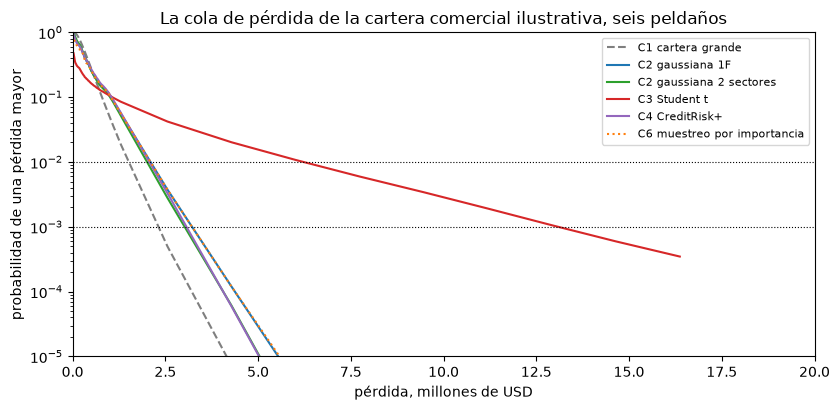

In [6]:
# Dibujar la probabilidad de excedencia de los peldaños versionados de la cartera comercial en un solo eje logarítmico
fig, ax = plt.subplots(figsize=(8.5, 4.2))
styles = (("c1-lhp", "tab:gray", "--", "C1 cartera grande"), ("c2-gaussian-1f", "tab:blue", "-", "C2 gaussiana 1F"),
          ("c2-gaussian-mf", "tab:green", "-", "C2 gaussiana 2 sectores"), ("c3-student-t", "tab:red", "-", "C3 Student t"),
          ("c4-creditrisk-plus", "tab:purple", "-", "C4 CreditRisk+"), ("c6-is-gaussian", "tab:orange", ":", "C6 muestreo por importancia"))
for rid, color, line, label in styles:
    curve = rungs[rid]["distribution"]
    ax.plot(np.array(curve["loss"]) / 1e6, np.maximum(1 - np.array(curve["cdf"]), 1e-9), color=color, linestyle=line, label=label)
for q in (0.99, 0.999):
    ax.axhline(1 - q, color="black", linestyle=":", linewidth=0.8)
ax.set_yscale("log")
ax.set_ylim(1e-5, 1)
ax.set_xlim(0, 20)
ax.set_xlabel("pérdida, millones de USD")
ax.set_ylabel("probabilidad de una pérdida mayor")
ax.set_title("La cola de pérdida de la cartera comercial ilustrativa, seis peldaños")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La figura compara los modelos. Una comparación más los pone en proporción: cuánto capital depende de la elección del modelo y cuánto de la incertidumbre de la correlación que todo modelo toma como insumo. La celda siguiente calcula el VaR al 99,9% de la cartera grande en los extremos del intervalo de razón de verosimilitud al 95% de la correlación del cuaderno 02, con la PD ajustada, y pone esa dispersión junto a la dispersión entre los peldaños versionados. Lee además el tamaño medido del estimador del intervalo en el simulador, de `grid-22.json`, porque un intervalo vale lo que vale su cobertura.

In [7]:
# Comparar la dispersión del capital por el intervalo de correlación con la dispersión entre los modelos
from riskvalidation.engines.vasicek import lhp_quantile

fit = ci["fit"]["maximum_likelihood"]
lgd = book["lgd_mean"]
scale = book["total_ead"] * lgd
print(f"{'rho':>8s} {'VaR 99.9% de la cartera grande':>34s} {'razón con el ajuste':>24s}")
points = (("ci_low", fit["rho"]["ci_low"]), ("ajuste", fit["rho"]["estimate"]), ("ci_high", fit["rho"]["ci_high"]))
by_rho = {label: scale * float(lhp_quantile(0.999, fit["pd"]["estimate"], rho_value)) for label, rho_value in points}
for label, rho_value in points:
    print(f"{rho_value:8.4f} {by_rho[label]:34,.0f} {by_rho[label] / by_rho['ajuste']:24.3f}   ({label})")
parameter_spread = by_rho["ci_high"] / by_rho["ci_low"]

models_999 = {rid: rungs[rid]["measures"][1]["var"] for rid in ("c1-lhp", "c2-gaussian-1f", "c2-gaussian-mf", "c4-creditrisk-plus", "c5-granularity", "c3-student-t")}
without_t = {k: v for k, v in models_999.items() if k != "c3-student-t"}
print("alto sobre bajo, intervalo de correlación (mismo modelo):", round(parameter_spread, 2))
print("mayor sobre menor entre los cinco modelos sin la cópula t:", round(max(without_t.values()) / min(without_t.values()), 2))
print("mayor sobre menor entre los seis modelos:", round(max(models_999.values()) / min(models_999.values()), 2))
print("tamaño medido de la prueba con el intervalo de máxima verosimilitud, 22 años:", grid22["impact"]["size_ml"]["value"], "| nominal 0.05")

     rho     VaR 99.9% de la cartera grande      razón con el ajuste
  0.0382                          1,645,635                    0.716   (ci_low)
  0.0637                          2,298,833                    1.000   (ajuste)
  0.1158                          3,682,446                    1.602   (ci_high)
alto sobre bajo, intervalo de correlación (mismo modelo): 2.24
mayor sobre menor entre los cinco modelos sin la cópula t: 1.43
mayor sobre menor entre los seis modelos: 5.7
tamaño medido de la prueba con el intervalo de máxima verosimilitud, 22 años: 0.0525 | nominal 0.05


## Resultados

- **La escalera se reproduce, y las cifras de impacto son cocientes de sus filas.** La escalera versionada tiene ocho filas, C1 a C6, una de las cuales, el muestreador por importancia t de Student, no corrió y no lleva ningún número. Los dos peldaños analíticos recalculados aquí, C1 y C4, coinciden con los versionados hasta 4e-3 y 5e-3 USD, el redondeo del archivo (calculado con el motor 0.7.0, instalado el 0.8.1). Las cuatro cifras de impacto recalculadas desde las filas de los peldaños son iguales a las guardadas: la cópula t de Student es 4,121813 veces la cópula gaussiana al 99,9%, la cópula gaussiana 1,382005 veces el límite de la cartera grande, el ajuste por granularidad 0,00983 de la exposición, y el capital ajustado 0,335915 del capital IRB.
- **En una cartera, cinco modelos quedan a menos de 43% unos de otros y uno no.** Al 99,9%, respecto del límite de la cartera grande (2.298.834 USD), la cópula gaussiana de dos sectores es 1,319, CreditRisk+ 1,339, la cópula gaussiana de un factor 1,382, el muestreo por importancia 1,394 y el límite más el ajuste por granularidad 1,428. La cópula t de Student es 5,696 veces el límite, 13.095.000 USD, y su déficit esperado es 16.000.767 USD frente a 3.683.187 USD de la cópula gaussiana. El supuesto de dependencia de cola es la mayor elección de estructura de la escalera, mayor que toda la dispersión entre los otros cinco modelos.
- **CreditRisk+ y la cópula gaussiana quedan cerca, como hace esperar el resultado de Gordy, y esto no es una prueba de él.** CreditRisk+ es 0,969 veces la cópula gaussiana al 99,9% en la cartera comercial y entre 0,928 y 1,000 en los cinco tipos de préstamo. Las dos comparten la PD y la varianza de la tasa de incumplimiento (la varianza Gamma se iguala por momentos a la tasa de incumplimiento de Vasicek), así que la cercanía está en parte incorporada. El dossier registra el enunciado de Gordy desde el resumen y marca su redacción como no verificada, y este cuaderno compara una calibración de cada familia en un conjunto de carteras.
- **La concentración cuesta entre 2,5% y 88% del VaR de la cartera grande, y el ajuste depende del capital que se le da.** El ajuste por granularidad sobre el VaR de la cartera grande es 0,428 para la cartera comercial (104 nombres efectivos), 0,437 para inmobiliario comercial (50), 0,090 para otro consumo (1.250), 0,025 para tarjetas de crédito (1.667) y 0,878 para residencial (595). La cifra residencial es grande porque el ajuste toma su capital $K_i$ de la fórmula IRB con la correlación regulatoria (el `k_source` versionado es `irb-regulatory-correlation`), mientras que el límite usa la correlación ajustada, que en residencial es 0,0129 frente a 0,15 de IRB: la razón mezcla dos correlaciones y no es una medida pura de concentración.
- **El insumo de correlación importa más que la elección entre los cinco modelos, y menos que la dependencia de cola.** El VaR al 99,9% de la cartera grande en los extremos del intervalo de razón de verosimilitud al 95% de la correlación es 1.645.635 y 3.682.446 USD, 0,716 y 1,602 veces el ajuste, una dispersión de 2,24 de un extremo al otro con el modelo fijo. Entre los cinco modelos sin la cópula t la dispersión es 1,43; con la cópula t es 5,7. El estimador detrás del intervalo tiene un tamaño medido de 0,0525 frente a 0,05 en el simulador con 22 años, así que el intervalo es honesto con años independientes, y el cuaderno 02 mostró que los años reales están fuertemente autocorrelacionados.
- **La brecha de código abierto, con sus límites.** El dossier no encontró una implementación en Python mantenida y con licencia permisiva de CreditMetrics ni de CreditRisk+ en una búsqueda con fecha 2026-10-04. Es un hallazgo de ausencia acotado por una búsqueda, y este cuaderno no puede ampliarlo. Lo que el cuaderno muestra es el otro lado: un motor con licencia permisiva cuyos peldaños analíticos reproducen una escalera versionada y cuyos peldaños de Monte Carlo concuerdan con ellos dentro de sus errores estándar (cuadernos 03 a 05).

Lo que este cuaderno no muestra: CreditMetrics en modo migración (no implementado), los modelos de concentración sectorial de la literatura (no corridos), el muestreo por importancia de cola pesada (la investigación no encontró un giro que implementar), ni cuál de los modelos debe adoptar un banco. La comparación es de modo incumplimiento sobre carteras ilustrativas.

## Resumen

- La literatura que encontró la investigación tiene modelos estructurales (CreditMetrics, cópulas gaussiana y t), el actuarial CreditRisk+, el límite de la cartera grande con su ajuste por granularidad y la simulación de eventos raros; Contraste corre todos salvo el modo migración de CreditMetrics, y registra que el muestreador por importancia t de Student no corrió.
- En una cartera y una calibración, cinco modelos quedan a menos de 43% unos de otros al 99,9%, y la cópula t de Student es 5,7 veces el límite: la dependencia de cola es la mayor elección estructural.
- CreditRisk+ y la cópula gaussiana coinciden dentro de 7% en cinco tipos de préstamo, en parte por construcción; es coherente con la equivalencia de Gordy y no es una prueba de ella.
- El insumo de correlación mueve el capital en un factor de 2,2 a lo largo de su intervalo al 95%, más que la elección entre los cinco modelos, y el tamaño del intervalo es 0,0525 con años independientes.
- La brecha de código abierto es un hallazgo de ausencia de una búsqueda con fecha 2026-10-04; Contraste la responde con un motor de licencia permisiva contrastado con anclas analíticas.

**Qué probar a continuación.** Recalcula la dispersión por parámetro para tarjetas de crédito o residencial desde sus propios intervalos y compárala con su dispersión por modelo. Luego abre el cuaderno 08 para la afirmación que demuestra este tema.

## Referencias

- Gordy, M. B. (2000), A comparative anatomy of credit risk models, Journal of Banking and Finance 24(1-2):119-149. https://doi.org/10.1016/S0378-4266(99)00054-0
- Gupton, G. M., Finger, C. C. y Bhatia, M. (1997), CreditMetrics Technical Document, J.P. Morgan, reissued by RiskMetrics Group (2007) and hosted by MSCI (authors as usually cited). https://www.msci.com/documents/10199/93396227-d449-4229-9143-24a94dab122f
- Li, D. X. (2000), On default correlation: a copula function approach, Journal of Fixed Income 9(4):43-54. https://doi.org/10.3905/jfi.2000.319253
- Frey, R. y McNeil, A. J. (2003), Dependent defaults in models of portfolio credit risk, Journal of Risk 6(1):59-92. https://doi.org/10.21314/jor.2003.089
- Demarta, S. y McNeil, A. J. (2005), The t copula and related copulas, International Statistical Review 73(1):111-129. https://doi.org/10.1111/j.1751-5823.2005.tb00254.x
- Haaf, H., Reiss, O. y Schoenmakers, J. (2004), Numerically stable computation of CreditRisk+, Journal of Risk 6(4):1-10. https://doi.org/10.21314/jor.2004.097
- Gordy, M. B. y Lutkebohmert, E. (2013), Granularity adjustment for regulatory capital assessment, International Journal of Central Banking 9(3):33-48. https://www.ijcb.org/sites/default/files/journal/v9n3/ijcb-v9n3-granularity-adjustment-regulatory-capital-assessment.pdf
- Glasserman, P. y Li, J. (2005), Importance sampling for portfolio credit risk, Management Science 51(11):1643-1656. https://doi.org/10.1287/mnsc.1050.0415
- Glasserman, P., Heidelberger, P. y Shahabuddin, P. (2002), Portfolio value-at-risk with heavy-tailed risk factors, Mathematical Finance 12(3):239-269. https://doi.org/10.1111/1467-9965.00141
- BCBS (2006), Studies on credit risk concentration: an overview of the issues and a synopsis of the results from the Research Task Force project, Working Paper No. 15. https://www.bis.org/publ/bcbs_wp15.pdf
- Dullmann, K. y Masschelein, N. (2007), A tractable model to measure sector concentration risk in credit portfolios, Journal of Financial Services Research 32(1-2):55-79. https://doi.org/10.1007/s10693-007-0014-3
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3):199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Board of Governors of the Federal Reserve System, Charge-off and delinquency rates on loans and leases at commercial banks, table chgallsa (public domain; licence class mirror-allowed). https://www.federalreserve.gov/releases/chargeoff/chgallsa.htm
- Credit Suisse First Boston (1997), CreditRisk+: A Credit Risk Management Framework: not accessed by the research (UNVERIFIED primary).
- Pykhtin, M. (2004), Multi-factor adjustment, Risk 17(3): bibliographic details not verified by the research (UNVERIFIED).
- Persisted research dossier 04 of this product (credit-risk models, state of the art), section H, in particular H.3 to H.8; the open-source search is dated 2026-10-04.
- Open Risk portfolioAnalytics (GPL-2.0), https://github.com/open-risk/portfolioAnalytics, named by the dossier among the implementations found.